In [1]:
import importlib

import numpy.random

import velocity_model
import torch
from matplotlib import pyplot

L = 5e6
v0 = 1e3
Tr = L/(2*v0)
origins = torch.tensor([2e6, 4e6], dtype=torch.int32)
h_tgrid = torch.linspace(0, 3600, steps=11, dtype=torch.double)
g_xranges_l = torch.tensor([1e6, 4.5e6], dtype=torch.int32)
g_xranges_u = torch.tensor([1.1e6, 4.6e6], dtype=torch.int32)

In [2]:
importlib.reload(velocity_model)
m = velocity_model.VelocityModel(L, True, origins, h_tgrid, g_xranges_l, g_xranges_u)

m.h_log = torch.nn.Parameter(torch.log(torch.tensor([1, 2, 4, 4, 2, 1, 0.25, 0.1, 0.1, 0.25, 1], dtype=torch.double)))
m.g_log = torch.nn.Parameter(torch.log(torch.tensor([10,0.1], dtype=torch.double)))

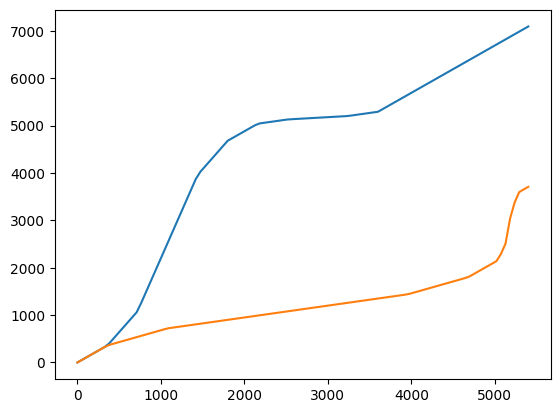

In [3]:
t = torch.linspace(0, 3600*1.5, steps=100)
pyplot.plot(t, m.H(t).detach().numpy(), label="H")
pyplot.plot(t, m.Hinv(t).detach().numpy(), label="Hinv")

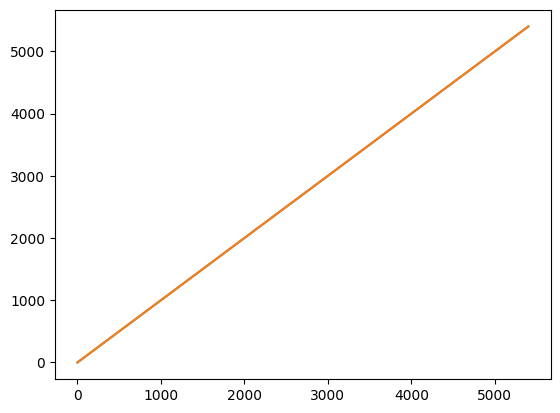

In [4]:
t = torch.linspace(0, 3600*1.5, steps=100)
pyplot.plot(t, m.Hinv(m.H(t)).detach().numpy(), label="H(Hinv)")
pyplot.plot(t, m.H(m.Hinv(t)).detach().numpy(), label="Hinv(H)")

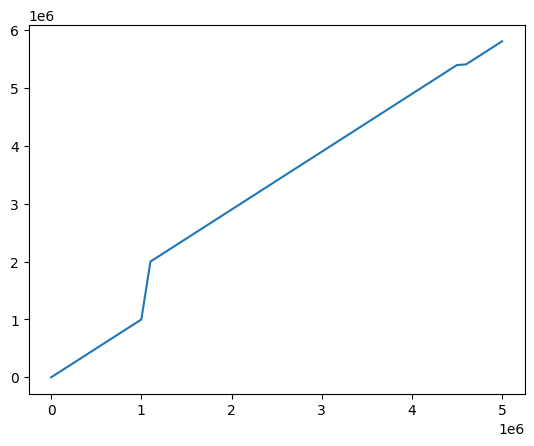

In [5]:
x = torch.linspace(0, L, steps=1000)
pyplot.plot(x, m.G_0(x).detach().numpy())

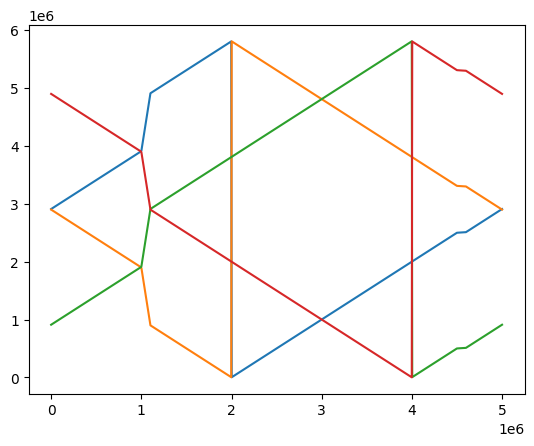

In [6]:
g1f = m.G(x, m.origins[0], torch.tensor([+1.0])).detach().numpy()
g1r = m.G(x, m.origins[0], torch.tensor([-1.0])).detach().numpy()
g2f = m.G(x, m.origins[1], torch.tensor([+1.0])).detach().numpy()
g2r = m.G(x, m.origins[1], torch.tensor([-1.0])).detach().numpy()
pyplot.plot(x, g1f, label="origin 1 fwd")
pyplot.plot(x, g1r, label="origin 1 rev")
pyplot.plot(x, g2f, label="origin 2 fwd")
pyplot.plot(x, g2r, label="origin 2 rev")

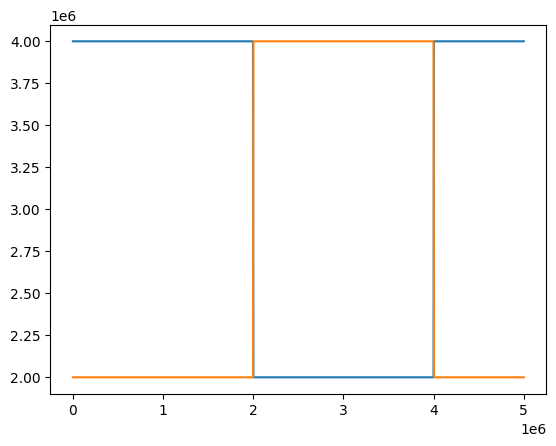

In [7]:
(i_l, i_r) = m.surrounding_origins(x)
pyplot.plot(x, m.origins[i_l], label="left")
pyplot.plot(x, m.origins[i_r], label="right")

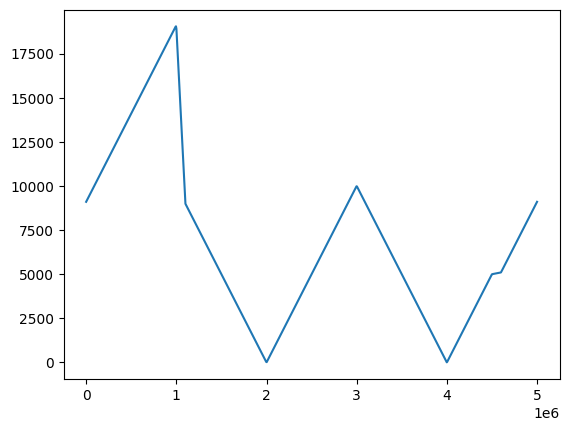

In [8]:
t = m.T(x).detach().numpy()
pyplot.plot(x, t)

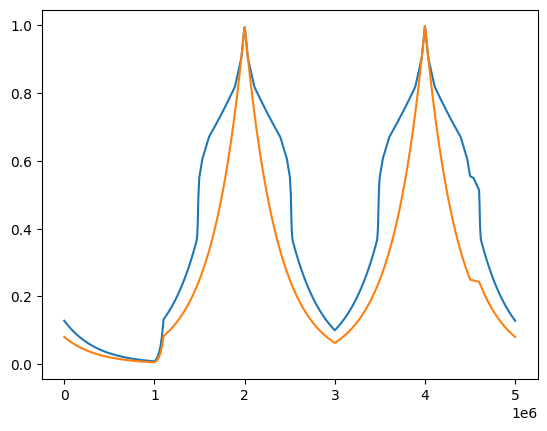

In [9]:
p = m.P(x).detach().numpy()
m0 = velocity_model.VelocityModel(L, True, origins, h_tgrid, g_xranges_l, g_xranges_u)
m0.g_log = torch.nn.Parameter(torch.log(torch.tensor([10,0.1], dtype=torch.double)))
p0 = m0.P(x).detach().numpy()
pyplot.plot(x, p, label="v=v(t)")
pyplot.plot(x, p0, label="v=v0")

In [10]:
coverage = 1e3
y_obs = torch.poisson(m.P(x) * coverage)
s_obs = torch.sqrt(y_obs)

l = velocity_model.VelocityModelLoss(x, y_obs, s_obs, m)
print(torch.sqrt(2 * (l() - m.penalty()) / x.size()[0]))

tensor([1.0087], dtype=torch.float64, grad_fn=<SqrtBackward0>)


In [11]:
with torch.no_grad():
    m.h_log[-1] = 1
    v1 = sum(m.Hinv(torch.tensor([6000], dtype=torch.double)))
    m.h_log[-1] = 10
    v2 = sum(m.Hinv(torch.tensor([6000], dtype=torch.double)))
    print(v1)
    print(v2)

tensor(3860.4586, dtype=torch.float64)
tensor(3600.0321, dtype=torch.float64)


In [12]:
v = sum(m.Hinv(torch.tensor([6000], dtype=torch.double)))
if m.h_log.grad is not None:
    m.h_log.grad.zero_()
v.backward(inputs=m.h_log)
print(m.h_log.grad)

tensor([-0.0163, -0.0327, -0.0654, -0.0654, -0.0327, -0.0163, -0.0041, -0.0016,
        -0.0016, -0.0041, -0.0321], dtype=torch.float64)


In [13]:
optimizer = torch.optim.SGD(m.parameters())
for n, p in m.named_parameters():
    print(n)
loss = l()
print("loss:")
print(loss)
optimizer.zero_grad()
loss.backward(retain_graph=True)
print("h_log:")
print(m.h_log)
print("grad h_log:")
print(m.h_log.grad)

v0
h_log
delay
g_log
loss:
tensor([962877.9577], dtype=torch.float64, grad_fn=<AddBackward0>)
h_log:
Parameter containing:
tensor([ 0.0000,  0.6931,  1.3863,  1.3863,  0.6931,  0.0000, -1.3863, -2.3026,
        -2.3026, -1.3863, 10.0000], dtype=torch.float64, requires_grad=True)
grad h_log:
tensor([-30494.0539, -45949.6500, -77055.5700, -63611.3613, -25712.6953,
        -13518.5528, -15905.6776, -23455.1807, -23246.1121, -14204.5816,
        100110.8157], dtype=torch.float64)
